### Actividad regresión logística

In [13]:
# Bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_curve, roc_auc_score, accuracy_score)

import statsmodels.api as sm
from scipy import stats

%matplotlib inline
sns.set_style('whitegrid')

In [14]:
# Dataset: Wine (3 clases originales; convertimos a clasificación binaria)
wine = load_wine()
X_w = pd.DataFrame(wine.data, columns=wine.feature_names)
y_w = pd.Series(wine.target, name='Clase')
df_w = pd.concat([X_w, y_w], axis=1)

# Clase 0 frente al resto: 1 = clase 0 original, 0 = clases 1 y 2
df_w['Clase_bin'] = (df_w['Clase'] == 0).astype(int)

print(f"Forma del dataset: {df_w.shape}")
print(f"Clases originales: {dict(y_w.value_counts().sort_index())}")
print(f"Clases binarias: {dict(df_w['Clase_bin'].value_counts().sort_index())}")
print(f"Proporción de vinos de clase 0: {df_w['Clase_bin'].mean():.3f}")
df_w.head()

Forma del dataset: (178, 15)
Clases originales: {0: 59, 1: 71, 2: 48}
Clases binarias: {0: 119, 1: 59}
Proporción de vinos de clase 0: 0.331


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Clase,Clase_bin
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,1
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,1
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,1
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,1
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,1


In [15]:
# Para simplificar el ejercicio, usamos 4 variables representativas
vars_w = ['alcohol', 'malic_acid', 'ash', 'total_phenols']

print("Estadísticas descriptivas por clase:\n")
print(df_w.groupby('Clase_bin')[vars_w].agg(['mean', 'std']).round(3))

Estadísticas descriptivas por clase:

          alcohol        malic_acid           ash        total_phenols       
             mean    std       mean    std   mean    std          mean    std
Clase_bin                                                                    
0          12.632  0.685      2.498  1.249  2.322  0.286         2.025  0.556
1          13.745  0.462      2.011  0.689  2.456  0.227         2.840  0.339


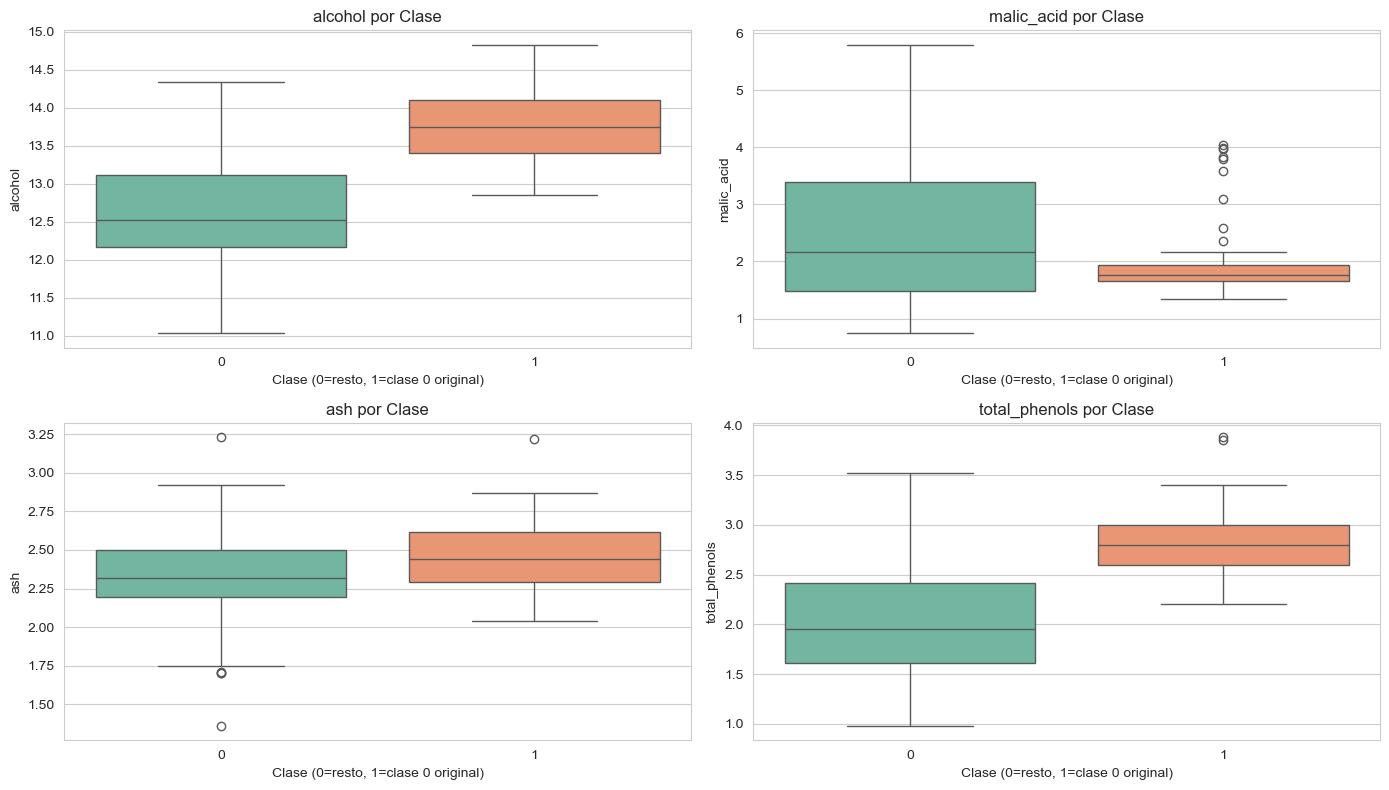

In [16]:
# Boxplots por clase binaria
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, var in enumerate(vars_w):
    sns.boxplot(x='Clase_bin', y=var, data=df_w, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{var} por Clase')
    axes[i].set_xlabel('Clase (0=resto, 1=clase 0 original)')

plt.tight_layout()
plt.show()

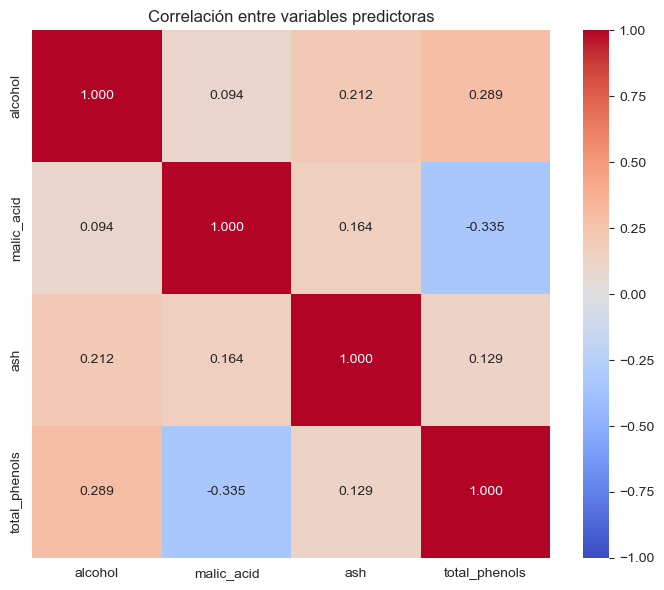

In [17]:
# Correlación entre variables
plt.figure(figsize=(7, 6))
sns.heatmap(df_w[vars_w].corr(), annot=True, cmap='coolwarm',
            center=0, vmin=-1, vmax=1, fmt='.3f')
plt.title('Correlación entre variables predictoras')
plt.tight_layout()
plt.show()

In [18]:
# Ajustar regresión logística con statsmodels (da p-valores y OR)
X_w_sm = sm.add_constant(df_w[vars_w])
y_w_sm = df_w['Clase_bin']

modelo_w = sm.Logit(y_w_sm, X_w_sm).fit(disp=False)
print(modelo_w.summary())

                           Logit Regression Results                           
Dep. Variable:              Clase_bin   No. Observations:                  178
Model:                          Logit   Df Residuals:                      173
Method:                           MLE   Df Model:                            4
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.6601
Time:                        23:19:14   Log-Likelihood:                -38.436
converged:                       True   LL-Null:                       -113.07
Covariance Type:            nonrobust   LLR p-value:                 2.929e-31
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -50.8074      8.817     -5.763      0.000     -68.087     -33.527
alcohol           3.0418      0.587      5.184      0.000       1.892       4.192
malic_acid       -0.2068      0.297     

In [19]:
# Odds Ratios con intervalos de confianza al 95%
or_w = pd.DataFrame({
    'Coeficiente': modelo_w.params,
    'OR': np.exp(modelo_w.params),
    'IC 2.5%': np.exp(modelo_w.conf_int()[0]),
    'IC 97.5%': np.exp(modelo_w.conf_int()[1]),
    'p-valor': modelo_w.pvalues
}).round(4)

print("=== ODDS RATIOS ===\n")
print(or_w)

=== ODDS RATIOS ===

               Coeficiente       OR  IC 2.5%  IC 97.5%  p-valor
const             -50.8074   0.0000   0.0000    0.0000   0.0000
alcohol             3.0418  20.9433   6.6317   66.1403   0.0000
malic_acid         -0.2068   0.8132   0.4539    1.4568   0.4869
ash                 0.9753   2.6518   0.3494   20.1258   0.3456
total_phenols       3.3311  27.9680   6.6002  118.5133   0.0000


In [20]:
# Predicciones de probabilidad
y_prob_w = modelo_w.predict(X_w_sm)
y_pred_w = (y_prob_w > 0.5).astype(int)

# Matriz de confusión
print("Matriz de confusión:\n")
print(confusion_matrix(y_w_sm, y_pred_w))

print("\nReporte de clasificación:\n")
print(classification_report(y_w_sm, y_pred_w,
                            target_names=['resto (1 y 2)', 'clase 0']))

print(f"Accuracy: {accuracy_score(y_w_sm, y_pred_w):.4f}")

Matriz de confusión:

[[110   9]
 [  9  50]]

Reporte de clasificación:

               precision    recall  f1-score   support

resto (1 y 2)       0.92      0.92      0.92       119
      clase 0       0.85      0.85      0.85        59

     accuracy                           0.90       178
    macro avg       0.89      0.89      0.89       178
 weighted avg       0.90      0.90      0.90       178

Accuracy: 0.8989


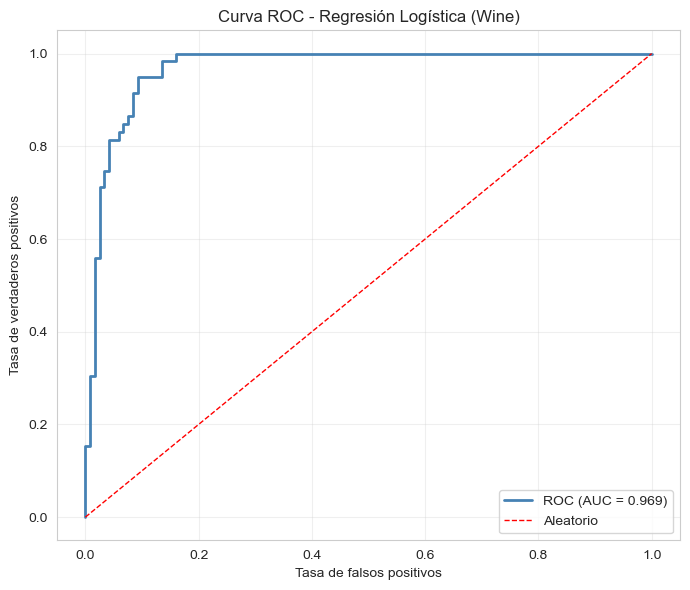

In [21]:
# Curva ROC
fpr, tpr, _ = roc_curve(y_w_sm, y_prob_w)
auc = roc_auc_score(y_w_sm, y_prob_w)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='steelblue', lw=2, label=f'ROC (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'r--', lw=1, label='Aleatorio')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC - Regresión Logística (Wine)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
# Implementación de la prueba de Hosmer-Lemeshow
def hosmer_lemeshow(y_true, y_prob, g=10):
    """
    Prueba de bondad de ajuste de Hosmer-Lemeshow.
    y_true: valores observados (0/1)
    y_prob: probabilidades predichas
    g: número de grupos (por defecto 10)
    """
    # Crear DataFrame auxiliar
    df_hl = pd.DataFrame({'y': y_true, 'p': y_prob})
    df_hl['grupo'] = pd.qcut(df_hl['p'], q=g, duplicates='drop')
    
    # Calcular observados y esperados por grupo
    hl_tabla = df_hl.groupby('grupo', observed=False).agg(
        n=('y', 'size'),
        observados=('y', 'sum'),
        esperados=('p', 'sum'),
        p_medio=('p', 'mean')
    )
    hl_tabla['obs_no'] = hl_tabla['n'] - hl_tabla['observados']
    hl_tabla['esp_no'] = hl_tabla['n'] - hl_tabla['esperados']
    
    # Estadístico HL
    HL = ((hl_tabla['observados'] - hl_tabla['esperados'])**2 /
          (hl_tabla['esperados'] * (1 - hl_tabla['p_medio']))).sum() \
       + ((hl_tabla['obs_no'] - hl_tabla['esp_no'])**2 /
          (hl_tabla['esp_no'] * (1 - hl_tabla['p_medio']))).sum()
    
    gl = len(hl_tabla) - 2
    p_valor = 1 - stats.chi2.cdf(HL, gl)
    
    return HL, gl, p_valor, hl_tabla

HL, gl, p_valor, tabla = hosmer_lemeshow(y_w_sm, y_prob_w, g=10)

print(f"Estadístico HL: {HL:.4f}")
print(f"Grados de libertad: {gl}")
print(f"p-valor: {p_valor:.4f}\n")

if p_valor > 0.05:
    print("✅ No se rechaza H0: el modelo tiene buen ajuste")
else:
    print("⚠️ Se rechaza H0: posible falta de ajuste")

print("\nTabla por grupos:")
print(tabla.round(3))

Estadístico HL: 335.0029
Grados de libertad: 8
p-valor: 0.0000

⚠️ Se rechaza H0: posible falta de ajuste

Tabla por grupos:
                       n  observados  esperados  p_medio  obs_no  esp_no
grupo                                                                   
(-0.000795, 0.00235]  18           0      0.018    0.001      18  17.982
(0.00235, 0.00503]    18           0      0.069    0.004      18  17.931
(0.00503, 0.0119]     18           0      0.154    0.009      18  17.846
(0.0119, 0.0233]      17           0      0.304    0.018      17  16.696
(0.0233, 0.0712]      18           0      0.774    0.043      18  17.226
(0.0712, 0.214]       18           3      2.414    0.134      15  15.586
(0.214, 0.608]        17           8      6.935    0.408       9  10.065
(0.608, 0.865]        18          15     13.542    0.752       3   4.458
(0.865, 0.971]        18          16     16.986    0.944       2   1.014
(0.971, 1.0]          18          17     17.806    0.989       1   0.194

In [23]:
# Pseudo R²
ll_modelo = modelo_w.llf        # log-verosimilitud del modelo completo
ll_nulo = modelo_w.llnull       # log-verosimilitud del modelo nulo
n = len(y_w_sm)

# McFadden
r2_mcfadden = 1 - (ll_modelo / ll_nulo)

# Cox-Snell
r2_coxsnell = 1 - np.exp((2 / n) * (ll_nulo - ll_modelo))

# Nagelkerke (ajusta Cox-Snell para que el máximo sea 1)
r2_nagelkerke = r2_coxsnell / (1 - np.exp((2 / n) * ll_nulo))

print("=== PSEUDO R² ===\n")
print(f"Log-verosimilitud modelo completo: {ll_modelo:.4f}")
print(f"Log-verosimilitud modelo nulo:     {ll_nulo:.4f}\n")
print(f"McFadden:    {r2_mcfadden:.4f}")
print(f"Cox-Snell:   {r2_coxsnell:.4f}")
print(f"Nagelkerke:  {r2_nagelkerke:.4f}")

=== PSEUDO R² ===

Log-verosimilitud modelo completo: -38.4358
Log-verosimilitud modelo nulo:     -113.0671

McFadden:    0.6601
Cox-Snell:   0.5677
Nagelkerke:  0.7892


In [24]:
# Comparación con sklearn
X_train, X_test, y_train, y_test = train_test_split(
    df_w[vars_w], df_w['Clase_bin'], test_size=0.3,
    random_state=42, stratify=df_w['Clase_bin']
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

modelo_sk = LogisticRegression(max_iter=1000)
modelo_sk.fit(X_train_sc, y_train)

y_pred_sk = modelo_sk.predict(X_test_sc)
y_prob_sk = modelo_sk.predict_proba(X_test_sc)[:, 1]

print("Accuracy en test: {:.4f}".format(accuracy_score(y_test, y_pred_sk)))
print("AUC en test:      {:.4f}".format(roc_auc_score(y_test, y_prob_sk)))
print("\nReporte de clasificación (test):\n")
print(classification_report(y_test, y_pred_sk,
                            target_names=['resto (1 y 2)', 'clase 0']))

Accuracy en test: 0.8333
AUC en test:      0.9259

Reporte de clasificación (test):

               precision    recall  f1-score   support

resto (1 y 2)       0.86      0.89      0.88        36
      clase 0       0.76      0.72      0.74        18

     accuracy                           0.83        54
    macro avg       0.81      0.81      0.81        54
 weighted avg       0.83      0.83      0.83        54

